# Datasheet Analysis
we read the excel datasheet and try to understand its content whilst paying attention to any possible anomalies

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# We read the given excel datasheet
df = pd.read_excel("Quality_Data_v3.xlsx", engine="openpyxl")

C:\Users\UpgradePC\anaconda3\envs\nllb-lora\lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [27]:
# We dont want to skip rows during display so we set the following options
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

### Basic datasheet info
We begin by checking basic datasheet info such as number of rows, columns, missing values and duplicated rows

In [28]:
df.head(5)

,Defect ID,Report Date,Report Time,Production Date,VIN,Car Model,Motor Type,Design Package,Station ID,Station Name,Part Number,Part Name,Supplier,Defect Name,Defect Category,Severity Rating,Inspector ID,Production Shift,Resolution Status,Resolution Timestamp,Resolution Time (hours),Root Cause Identified,Rework Time (minutes)
0,DEF-2026-000001,2026-01-01,00:44,2026-01-01,WBAX00000118,iX0M,Long Range,Race,ST-14,Brake System Assembly,400495,Sensor Module,Nordwerk Systems,Sensor Failure,Electrical,5,INS-018,Night,Resolved,2026-01-01 09:54,9.18,NaN,127.0
1,DEF-2026-000002,2026-01-01,01:16,2026-01-01,WBAX00000271,Base,Long Range,Luxury,ST-01,Body Shop Framing,400161,Body Panel,Hoffmann Metallwerk,Paint Run,Cosmetic,7,INS-029,Night,Resolved,2026-01-01 09:16,8.01,No,55.0
2,DEF-2026-000003,2026-01-01,01:27,2026-01-01,WBAX00000083,Long,Long Range,Offroad,ST-08,Wire Harness Installation,400473,Control Unit,Nordwerk Systems,Control Unit Fault,Electrical,3,INS-003,Night,Resolved,2026-01-01 05:10,3.73,No,109.0
3,DEF-2026-000004,2026-01-01,02:34,2026-01-01,WBAX00000268,Base,Long Range,Race,ST-02,Body Shop Welding,400161,Body Panel,Hoffmann Metallwerk,Colour Mismatch,Cosmetic,7,INS-002,Night,Resolved,2026-01-01 10:13,7.66,Yes,88.0
4,DEF-2026-000005,2026-01-01,03:29,2026-01-01,WBAX00000069,Base,High Performance,Race,ST-09,EV Battery Installation,400344,Harness Connector,Kessler-Automotive,Connector Corrosion,Electrical,3,INS-019,Night,Resolved,2026-01-01 09:41,6.21,Yes,91.0


In [29]:
print("Datasheet Rows:", len(df))
print("Datasheet Columns:", len(df.columns))

Datasheet Rows: 8198
Datasheet Columns: 23


In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8198 entries, 0 to 8197
Data columns (total 23 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Defect ID                8198 non-null   object 
 1   Report Date              8198 non-null   object 
 2   Report Time              8198 non-null   object 
 3   Production Date          8198 non-null   object 
 4   VIN                      8198 non-null   object 
 5   Car Model                8198 non-null   object 
 6   Motor Type               8198 non-null   object 
 7   Design Package           8198 non-null   object 
 8   Station ID               8198 non-null   object 
 9   Station Name             8198 non-null   object 
 10  Part Number              8198 non-null   int64  
 11  Part Name                8198 non-null   object 
 12  Supplier                 8198 non-null   object 
 13  Defect Name              8198 non-null   object 
 14  Defect Category         

In [31]:
print("Duplicate rows:", df.duplicated().sum()) # We check if any exact same rows were inserted twice
print("Duplicate Defect IDs:", df["Defect ID"].duplicated().sum()) # We check if any rows has the same Defect IDs

Duplicate rows: 0
Duplicate Defect IDs: 0


## Conflicting data
We investigate different defect reports and find some VIN (Vehicle Identification Number) were reported with different Car model, Motor type and design package. We cannot proceed and delete such information because it's not feasible for us to find out which report is correct.

In [32]:
vehicle_columns = [
    "Car Model",
    "Motor Type",
    "Design Package"
]

conflicts = df.groupby("VIN")[vehicle_columns].nunique()

conflicting_vins = conflicts[
    (conflicts > 1).any(axis=1)
]

print("VINs with conflicting details:", len(conflicting_vins))
conflicting_vins.head()

VINs with conflicting details: 517


,Car Model,Motor Type,Design Package
VIN,,,
WBAX00000069,1,2,2
WBAX00000084,2,2,1
WBAX00000160,2,2,3
WBAX00000203,2,2,1
WBAX00000221,2,2,1


## Missing values
We double check for missing values but the only columns with missing values were the "Root Cause Identified","Resolution Timestamp", "Resolution Time (hours)","Rework Time (minutes)". The BMW presentation explicitly mentions those aren't missing data, it only means the defect hasn't been resolved yet. So we take no action here

In [33]:
missing_values = df.isna().sum()

display(missing_values[missing_values > 0].sort_values(ascending=False)) # The 4 rows with missing values aren't really missing values, they are just defects that haven't been resolved.

Root Cause Identified      1695
Resolution Timestamp       1251
Resolution Time (hours)    1251
Rework Time (minutes)      1251
dtype: int64

## Duplicate reports
In the following section we checked for repeated combinations of VIN and Defect Name to identify potentially duplicated defect reports. 
These records were flagged for inspection rather than automatically removed, as repeated reports may represent genuine recurring defects.

In [34]:
duplicate_mask = df.duplicated(
    subset=["VIN", "Defect Name"],
    keep=False
)

duplicate_defects = df[duplicate_mask].sort_values(
    by=["VIN", "Defect Name"]
)

print("Rows with repeated VIN and Defect Name:", len(duplicate_defects))

display(duplicate_defects)

Rows with repeated VIN and Defect Name: 116


,Defect ID,Report Date,Report Time,Production Date,VIN,Car Model,Motor Type,Design Package,Station ID,Station Name,Part Number,Part Name,Supplier,Defect Name,Defect Category,Severity Rating,Inspector ID,Production Shift,Resolution Status,Resolution Timestamp,Resolution Time (hours),Root Cause Identified,Rework Time (minutes)
210,DEF-2026-000211,2026-01-05,17:54,2026-01-05,WBAX00001327,Alpina,Long Range,Luxury,ST-09,EV Battery Installation,400415,Battery Housing,Voltania Cells,Coolant Leak,Functional,4,INS-013,Afternoon,Resolved,2026-01-06 03:35,9.69,Yes,53.0
211,DEF-2026-000212,2026-01-05,18:05,2026-01-05,WBAX00001327,Alpina,Long Range,Luxury,ST-09,EV Battery Installation,400415,Battery Housing,Voltania Cells,Coolant Leak,Functional,4,INS-022,Afternoon,Resolved,2026-01-06 03:35,9.69,Yes,53.0
330,DEF-2026-000331,2026-01-08,06:23,2026-01-08,WBAX00002118,Base,Long Range,Luxury,ST-13,Windshield Installation,400149,Body Panel,Hoffmann Metallwerk,Paint Run,Cosmetic,9,INS-022,Morning,Resolved,2026-01-08 14:14,7.86,NaN,60.0
400,DEF-2026-000401,2026-01-09,12:50,2026-01-08,WBAX00002118,Base,High Performance,Luxury,ST-01,Body Shop Framing,400149,Body Panel,Hoffmann Metallwerk,Paint Run,Cosmetic,8,INS-039,Morning,Resolved,2026-01-09 17:21,4.53,No,48.0
537,DEF-2026-000538,2026-01-13,11:33,2026-01-13,WBAX00003632,Base,High Performance,Luxury,ST-17,Charging System Inspection,400344,Harness Connector,Kessler-Automotive,Connector Corrosion,Electrical,4,INS-025,Morning,In Progress,NaN,NaN,NaN,NaN
707,DEF-2026-000708,2026-01-16,21:54,2026-01-13,WBAX00003632,Long,Long Range,Race,ST-08,Wire Harness Installation,400330,Harness Connector,Kessler-Automotive,Connector Corrosion,Electrical,4,INS-009,Afternoon,In Progress,NaN,NaN,NaN,NaN
675,DEF-2026-000676,2026-01-16,06:58,2026-01-16,WBAX00004640,Pick-Up,High Performance,Race,ST-01,Body Shop Framing,400118,Body Panel,Hoffmann Metallwerk,Paint Run,Cosmetic,9,INS-001,Morning,Resolved,2026-01-16 19:42,12.74,Yes,73.0
692,DEF-2026-000693,2026-01-16,14:22,2026-01-16,WBAX00004640,iX0M,Long Range,Luxury,ST-04,Paint Shop Topcoat,400161,Body Panel,Hoffmann Metallwerk,Paint Run,Cosmetic,10,INS-031,Afternoon,Resolved,2026-01-17 00:25,10.06,Yes,12.0
1361,DEF-2026-001362,2026-02-02,01:46,2026-02-02,WBAX00009803,Long,Long Range,Offroad,ST-08,Wire Harness Installation,400458,Control Unit,Nordwerk Systems,Sensor Failure,Electrical,4,INS-017,Night,Resolved,2026-02-02 12:05,10.32,Yes,122.0
1384,DEF-2026-001385,2026-02-02,13:55,2026-02-02,WBAX00009803,Long,High Performance,Race,ST-14,Brake System Assembly,400523,Sensor Module,Nordwerk Systems,Sensor Failure,Electrical,3,INS-040,Morning,Resolved,2026-02-02 16:43,2.80,Yes,138.0


In [35]:
# Count repeated defect names for each VIN
duplicate_counts = (
    df.groupby(["VIN", "Defect Name"])
    .size()
    .reset_index(name="Report Count")
    .query("`Report Count` > 1")
    .sort_values("Report Count", ascending=False)
)

print("Number of repeated VIN–Defect combinations:", len(duplicate_counts))

display(duplicate_counts)

Number of repeated VIN–Defect combinations: 58


,VIN,Defect Name,Report Count
215,WBAX00001327,Coolant Leak,2
7038,WBAX00047395,Frame Misalignment,2
5886,WBAX00040139,Sensor Failure,2
5953,WBAX00040662,Colour Mismatch,2
5983,WBAX00040900,Frame Misalignment,2
6058,WBAX00041333,Frame Misalignment,2
6123,WBAX00041670,Orange Peel Finish,2
6295,WBAX00042812,Trim Misfit,2
6336,WBAX00043110,Weld Seam Crack,2
6418,WBAX00043579,Frame Misalignment,2


## Categorical data inspection
In this section we try to check all unique values assigned to categorical data such as model, motor type, design package, station name etc etc...
We notice that certain defect names, station names appear misspelled in certain reports. This sort of anomalies can be easily fixed using fuzzy string matching.
We also noticed how the "root cause identified" isn't normalised some are assigned NaN value instead of No

In [36]:
exclude_cols = [
    "Defect ID", "Inspector ID", "VIN",
    "Report Date", "Report Time", "Production Date",
    "Resolution Timestamp"
]

for col in df.select_dtypes(exclude="number").columns:
    if col not in exclude_cols:
        print(f"\n{col} ({df[col].nunique()} unique values):")
        print(df[col].unique())


Car Model (5 unique values):
['iX0M' 'Base' 'Long' 'Alpina' 'Pick-Up']

Motor Type (2 unique values):
['Long Range' 'High Performance']

Design Package (3 unique values):
['Race' 'Luxury' 'Offroad']

Station ID (18 unique values):
['ST-14' 'ST-01' 'ST-08' 'ST-02' 'ST-09' 'ST-06' 'ST-18' 'ST-13' 'ST-17'
 'ST-11' 'ST-16' 'ST-12' 'ST-03' 'ST-04' 'ST-07' 'ST-05' 'ST-10' 'ST-15']

Station Name (76 unique values):
['Brake System Assembly' 'Body Shop Framing' 'Wire Harness Installation'
 'Body Shop Welding' 'EV Battery Installation' 'Underbody Assembly'
 'Final Quality Gate' 'Windshield Installation'
 'Charging System Inspection' 'Dashboard Installation'
 'Tire and Rim Mounting' 'Seat Installation' 'Paint Shop Primer'
 'Paint Shop Topcoat' 'Door Panel Fitting' 'Paint Inspection Booth'
 'Battery End-of-Line Test' 'Dashboar Installation'
 'Steering Column Assembly' 'Paint Shop Tocoat' 'Tire and Rm Mounting'
 'Battery nd-of-Line Test' 'BodyS hop Welding'
 'Chargnig System Inspection' 'Body Shop

## Data Cleaning and Standardization

This section addresses missing values in the Root Cause Identified column
and inconsistent naming in the Defect Name and Station Name columns.

Fuzzy string matching is used to identify spelling variations and map
them to standardized names.

In [37]:
df["Root Cause Identified"] = df["Root Cause Identified"].fillna("No")

df["Root Cause Identified"].value_counts(dropna=False)

Root Cause Identified
Yes    5163
No     3035
Name: count, dtype: int64

In [38]:
%pip install rapidfuzz

Note: you may need to restart the kernel to use updated packages.


In [39]:
from rapidfuzz import process, fuzz

In [40]:
correct_defect_names = [
    "Sensor Failure",
    "Paint Run",
    "Control Unit Fault",
    "Colour Mismatch",
    "Connector Corrosion",
    "Brake Line Defect",
    "Fastener Torque Deviation",
    "Frame Misalignment",
    "Orange Peel Finish",
    "Panel Gap Misalignment",
    "Trim Misfit",
    "Windshield Chip",
    "Charging Fault",
    "Rattle Noise",
    "Battery Module Fault",
    "Paint Scratch",
    "Weld Seam Crack",
    "Upholstery Tear",
    "Loose Wiring",
    "Water Ingress",
    "Coolant Leak",
    "Steering Play"
]

correct_station_names = [
    "Brake System Assembly",
    "Body Shop Framing",
    "Wire Harness Installation",
    "Body Shop Welding",
    "EV Battery Installation",
    "Underbody Assembly",
    "Final Quality Gate",
    "Windshield Installation",
    "Charging System Inspection",
    "Dashboard Installation",
    "Tire and Rim Mounting",
    "Seat Installation",
    "Paint Shop Primer",
    "Paint Shop Topcoat",
    "Door Panel Fitting",
    "Paint Inspection Booth",
    "Battery End-of-Line Test",
    "Steering Column Assembly"
]

In [41]:
def fuzzy_correct(value, valid_names, threshold=85):
    if pd.isna(value):
        return value

    match = process.extractOne(
        str(value),
        valid_names,
        scorer=fuzz.ratio,
        processor=lambda s: s.lower()
    )

    if match and match[1] >= threshold:
        return match[0]

    return value

## Manual inspection of the proposed correction
We manually inspect the proposed value for both the defect name and station name

In [42]:
for column, valid_names in [
    ("Defect Name", correct_defect_names),
    ("Station Name", correct_station_names)
]:
    unique_values = df[column].dropna().unique()

    mapping = pd.DataFrame({
        "Original": unique_values,
        "Suggested": [
            fuzzy_correct(value, valid_names)
            for value in unique_values
        ]
    })

    changes = mapping[mapping["Original"] != mapping["Suggested"]]

    print(f"\n{column}: {len(changes)} proposed corrections")
    display(changes)


Defect Name: 100 proposed corrections


,Original,Suggested
21,Wed Seam Crack,Weld Seam Crack
23,PaintS cratch,Paint Scratch
24,Weld SeamC rack,Weld Seam Crack
25,FrameM isalignment,Frame Misalignment
26,OrangeP eel Finish,Orange Peel Finish
27,SensorF ailure,Sensor Failure
28,CoOlaNt LEAk,Coolant Leak
29,rAtTLE noiSE,Rattle Noise
30,Tri Misfit,Trim Misfit
31,coLour MISMAtcH,Colour Mismatch



Station Name: 58 proposed corrections


,Original,Suggested
17,Dashboar Installation,Dashboard Installation
19,Paint Shop Tocoat,Paint Shop Topcoat
20,Tire and Rm Mounting,Tire and Rim Mounting
21,Battery nd-of-Line Test,Battery End-of-Line Test
22,BodyS hop Welding,Body Shop Welding
23,Chargnig System Inspection,Charging System Inspection
24,Body Shop Framnig,Body Shop Framing
25,BodyS hop Framing,Body Shop Framing
26,Paint hSop Primer,Paint Shop Primer
27,Windshield Instllation,Windshield Installation


## Applying changes to the dataset
We apply the proposed correction after manually verifying them to be correct

In [43]:
df["Defect Name"] = df["Defect Name"].apply(
    lambda x: fuzzy_correct(x, correct_defect_names)
)

df["Station Name"] = df["Station Name"].apply(
    lambda x: fuzzy_correct(x, correct_station_names)
)

We double-check to see if there's any remaining mistakes

In [44]:
print("Unique defect names:", df["Defect Name"].nunique())
print("Unique station names:", df["Station Name"].nunique())

print("\nUnmatched defect names:")
print(set(df["Defect Name"].dropna()) - set(correct_defect_names))

print("\nUnmatched station names:")
print(set(df["Station Name"].dropna()) - set(correct_station_names))

Unique defect names: 22
Unique station names: 18

Unmatched defect names:
set()

Unmatched station names:
set()


## Export Cleaned Dataset to JSON

After cleaning and standardizing the dataset, the final DataFrame is exported
to JSON format for use in the BMW Quality Dashboard.

The export preserves the original column names and uses one JSON object per
defect report. This saves it into the same folder as the notebook. it needs to be manually placed into the ./public/data folder of the dashboard

In [45]:
df.to_json("defects.json", orient="records", indent=2, force_ascii=False)
print(f"Exported {len(df)} defect reports")

Exported 8198 defect reports


In [46]:
# Top 5 most common defects and their share of all defect reports

total_defects = len(df)

top_5_defects = (
    df["Defect Name"]
    .value_counts()
    .head(5)
    .rename_axis("Defect Name")
    .reset_index(name="Report Count")
)

top_5_defects["Share of All Defects (%)"] = (
    top_5_defects["Report Count"] / total_defects * 100
).round(2)

print(f"Total defect reports: {total_defects:,}")
display(top_5_defects)

print(
    f"\nCombined share of top 5 defects: "
    f"{top_5_defects['Share of All Defects (%)'].sum():.2f}%"
)

Total defect reports: 8,198


,Defect Name,Report Count,Share of All Defects (%)
0,Sensor Failure,677,8.26
1,Paint Scratch,565,6.89
2,Connector Corrosion,551,6.72
3,Water Ingress,536,6.54
4,Loose Wiring,524,6.39



Combined share of top 5 defects: 34.80%


# TASK 6
## On page 3 of the powerpoint presentation we are told severity "1" is considered most severe, on the following page number 4 we are told severity "10" is most severe. I will do this task taking in consideration Severity "1" is most severe

We visualise the mean, median resolution time for each severity.

Reports analysed: 6,947
Pearson correlation: -0.032
Spearman correlation: 0.144


,count,mean,median
Severity Rating,,,
1,117,4.16,3.56
2,246,6.87,3.46
3,1112,10.25,5.74
4,1101,9.55,4.80
5,907,7.80,4.80
6,732,8.38,5.42
7,844,6.91,5.54
8,815,7.58,5.94
9,480,7.77,6.28


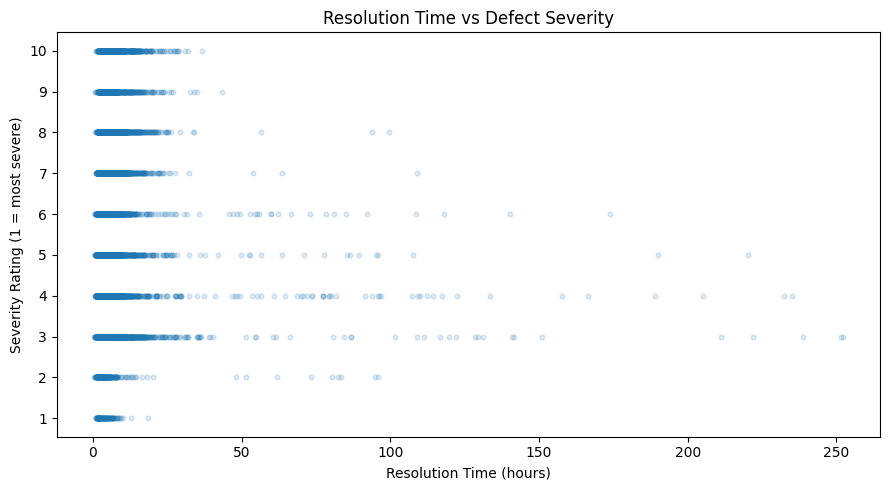

In [50]:
# Only resolved reports with valid resolution times and severity ratings
analysis = df[
    (df["Resolution Status"] == "Resolved")
].copy()

# Measure relationship
pearson = analysis["Resolution Time (hours)"].corr(
    analysis["Severity Rating"], method="pearson"
)
spearman = analysis["Resolution Time (hours)"].corr(
    analysis["Severity Rating"], method="spearman"
)

print(f"Reports analysed: {len(analysis):,}")
print(f"Pearson correlation: {pearson:.3f}")
print(f"Spearman correlation: {spearman:.3f}")

# Compare average resolution times by severity
summary = (
    analysis.groupby("Severity Rating")["Resolution Time (hours)"]
    .agg(["count", "mean", "median"])
    .round(2)
)

display(summary)

plt.figure(figsize=(9, 5))
plt.scatter(
    analysis["Resolution Time (hours)"],
    analysis["Severity Rating"],
    alpha=0.15,
    s=12
)
plt.xlabel("Resolution Time (hours)")
plt.ylabel("Severity Rating (1 = most severe)")
plt.title("Resolution Time vs Defect Severity")
plt.yticks(range(1, 11))
plt.tight_layout()
plt.show()

In the following section we repeat the exact same steps but sorted by either median or mean just to make it more clear

In [51]:
# Sort by average (mean) resolution time
print("Severity ratings sorted by MEAN resolution time:")
display(summary.sort_values("mean", ascending=False))

# Sort by median resolution time
print("Severity ratings sorted by MEDIAN resolution time:")
display(summary.sort_values("median", ascending=False))

Severity ratings sorted by MEAN resolution time:


,count,mean,median
Severity Rating,,,
3,1112,10.25,5.74
4,1101,9.55,4.80
10,593,8.44,7.11
6,732,8.38,5.42
5,907,7.80,4.80
9,480,7.77,6.28
8,815,7.58,5.94
7,844,6.91,5.54
2,246,6.87,3.46


Severity ratings sorted by MEDIAN resolution time:


,count,mean,median
Severity Rating,,,
10,593,8.44,7.11
9,480,7.77,6.28
8,815,7.58,5.94
3,1112,10.25,5.74
7,844,6.91,5.54
6,732,8.38,5.42
4,1101,9.55,4.80
5,907,7.80,4.80
1,117,4.16,3.56


In [52]:
category_summary = (
    analysis.groupby("Defect Category")["Resolution Time (hours)"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median"
    )
    .sort_values("Median", ascending=False)
    .round(2)
)

display(category_summary)

,Count,Mean,Median
Defect Category,,,
Cosmetic,2011,7.56,6.22
Electrical,2053,10.52,5.93
Functional,1444,8.17,5.14
Structural,1186,7.01,4.38
Safety,253,4.54,3.78


In [53]:
name_summary = (
    analysis.groupby("Defect Name")["Resolution Time (hours)"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median"
    )
    .sort_values("Median", ascending=False)
    .round(2)
)

# Only show defect types with at least 20 resolved reports
display(name_summary[name_summary["Count"] >= 20])

,Count,Mean,Median
Defect Name,,,
Loose Wiring,436,12.24,9.09
Connector Corrosion,463,10.75,8.80
Trim Misfit,361,8.03,6.64
Orange Peel Finish,351,7.81,6.59
Paint Run,299,7.79,6.34
Colour Mismatch,306,7.30,6.26
Upholstery Tear,76,7.65,6.22
Windshield Chip,140,6.62,5.93
Paint Scratch,478,7.30,5.76


In [54]:
from scipy.stats import kruskal

# Test differences between defect categories
category_groups = [
    group["Resolution Time (hours)"].values
    for _, group in analysis.groupby("Defect Category")
]

category_stat, category_p = kruskal(*category_groups)

# Test differences between defect names
name_groups = [
    group["Resolution Time (hours)"].values
    for _, group in analysis.groupby("Defect Name")
]

name_stat, name_p = kruskal(*name_groups)

print(f"Defect Category p-value: {category_p:.6g}")
print(f"Defect Name p-value: {name_p:.6g}")

Defect Category p-value: 1.43181e-61
Defect Name p-value: 3.75491e-147


In [56]:
severity_data = df.copy()
severity_data["Severity Rating"] = pd.to_numeric(
    severity_data["Severity Rating"], errors="coerce"
)
severity_data = severity_data[
    severity_data["Severity Rating"].between(1, 10)
]

for column in ["Defect Category", "Defect Name"]:
    groups = [
        group["Severity Rating"].values
        for _, group in severity_data.groupby(column)
    ]
    statistic, p = kruskal(*groups)
    print(f"{column}: H={statistic:.2f}, p={p:.6g}")

Defect Category: H=5613.03, p=0
Defect Name: H=5913.52, p=0


### In the followiong section we check the mean reduction when we remove outliers to verify whether the average is being pushed up by outliers

In [57]:
def check_category_outliers(group):
    times = group["Resolution Time (hours)"]

    q1 = times.quantile(0.25)
    q3 = times.quantile(0.75)
    iqr = q3 - q1

    upper_bound = q3 + 1.5 * iqr

    outliers = times > upper_bound
    without_outliers = times[~outliers]

    return pd.Series({
        "Count": len(times),
        "Mean": times.mean(),
        "Median": times.median(),
        "Outliers": outliers.sum(),
        "Outlier %": outliers.mean() * 100,
        "Mean without outliers": without_outliers.mean(),
        "Mean reduction": times.mean() - without_outliers.mean()
    })

category_outliers = (
    analysis.groupby("Defect Category")
    .apply(check_category_outliers, include_groups=False)
    .sort_values("Mean reduction", ascending=False)
    .round(2)
)

display(category_outliers)

,Count,Mean,Median,Outliers,Outlier %,Mean without outliers,Mean reduction
Defect Category,,,,,,,
Electrical,2053.0,10.52,5.93,150.0,7.31,6.65,3.87
Functional,1444.0,8.17,5.14,94.0,6.51,5.53,2.64
Structural,1186.0,7.01,4.38,89.0,7.50,4.67,2.34
Cosmetic,2011.0,7.56,6.22,90.0,4.48,6.84,0.72
Safety,253.0,4.54,3.78,6.0,2.37,4.30,0.24


### We repeat same experiment for each individual defect and we confirm that outliers are pushing up the avg resolution time significantly

In [58]:
def check_name_outliers(group):
    times = group["Resolution Time (hours)"]

    q1 = times.quantile(0.25)
    q3 = times.quantile(0.75)
    upper_bound = q3 + 1.5 * (q3 - q1)

    outliers = times > upper_bound
    without_outliers = times[~outliers]

    return pd.Series({
        "Count": len(times),
        "Mean": times.mean(),
        "Median": times.median(),
        "Outliers": outliers.sum(),
        "Outlier %": outliers.mean() * 100,
        "Mean without outliers": without_outliers.mean(),
        "Mean reduction": times.mean() - without_outliers.mean()
    })

name_outliers = (
    analysis.groupby("Defect Name")
    .apply(check_name_outliers, include_groups=False)
    .sort_values("Mean reduction", ascending=False)
    .round(2)
)

display(name_outliers)

,Count,Mean,Median,Outliers,Outlier %,Mean without outliers,Mean reduction
Defect Name,,,,,,,
Battery Module Fault,226.0,28.04,4.78,36.0,15.93,4.92,23.12
Water Ingress,458.0,12.07,5.11,44.0,9.61,5.32,6.75
Weld Seam Crack,394.0,10.19,4.45,43.0,10.91,4.62,5.58
Loose Wiring,436.0,12.24,9.09,23.0,5.28,10.39,1.85
Connector Corrosion,463.0,10.75,8.80,33.0,7.13,9.00,1.74
Upholstery Tear,76.0,7.65,6.22,5.0,6.58,6.63,1.03
Trim Misfit,361.0,8.03,6.64,23.0,6.37,7.05,0.99
Fastener Torque Deviation,392.0,5.80,4.58,24.0,6.12,4.94,0.86
Rattle Noise,408.0,6.63,5.36,21.0,5.15,5.82,0.81


## Does resolution time differ between day and night shifts? ----> Based on our data no

In [60]:
shift_summary = (
    analysis.groupby("Production Shift")["Resolution Time (hours)"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median"
    )
    .round(2)
)

display(shift_summary)

,Count,Mean,Median
Production Shift,,,
Afternoon,2500,8.09,5.38
Morning,2952,8.87,5.64
Night,1495,7.78,5.19


## Next we check the type of defects each station has reported

In [63]:
station_categories = pd.crosstab(
    df["Station Name"],
    df["Defect Category"]
)

display(station_categories)

Defect Category,Cosmetic,Electrical,Functional,Safety,Structural
Station Name,,,,,
Battery End-of-Line Test,0,343,0,0,0
Body Shop Framing,118,0,142,0,246
Body Shop Welding,142,0,131,0,228
Brake System Assembly,0,139,0,71,86
Charging System Inspection,0,327,0,0,0
Dashboard Installation,63,280,85,0,0
Door Panel Fitting,522,0,279,0,115
EV Battery Installation,0,447,56,0,0
Final Quality Gate,264,180,202,0,14


## Now we proceed to check if different defect categories resolution time avg differs depending on what station reports

In [64]:
station_category = (
    analysis.groupby(["Defect Category", "Station Name"])
    ["Resolution Time (hours)"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median"
    )
    .round(2)
)

# Exclude combinations with very few reports
station_category = station_category[
    station_category["Count"] >= 20
]

display(station_category)

Count   Mean  Median
Defect Category Station Name                                    
Cosmetic        Body Shop Framing             104   7.80    6.16
                Body Shop Welding             122   7.71    6.30
                Dashboard Installation         50   8.32    6.65
                Door Panel Fitting            430   7.01    5.88
                Final Quality Gate            227   7.02    5.93
                Paint Inspection Booth        195   8.43    6.88
                Paint Shop Primer             233   7.62    6.52
                Paint Shop Topcoat            242   7.79    6.12
                Seat Installation             171   7.93    6.83
                Tire and Rim Mounting          62   6.92    5.60
                Windshield Installation       175   7.64    6.25
Electrical      Battery End-of-Line Test      281   5.37    4.52
                Brake System Assembly         117   4.90    4.20
                Charging System Inspection    258   9.83    7.52
                Dashboard Installation        241   5.45    4.51
                EV Battery Installation       371  24.30    8.92
                Final Quality Gate            155   5.95    4.97
                Steering Column Assembly      138   5.55    3.98
                Wire Harness Installation     492  10.07    7.89
Functional      Body Shop Framing             115   8.13    4.85
                Body Shop Welding             117   7.71    5.55
                Dashboard Installation         75   6.25    5.36
                Door Panel Fitting            227   7.56    4.71
                EV Battery Installation        47   5.06    3.90
                Final Quality Gate            180   6.75    5.08
                Paint Inspection Booth         86   8.63    5.18
                Paint Shop Primer             113  10.40    5.76
                Paint Shop Topcoat            171   9.39    5.18
                Seat Installation             115   7.74    6.61
                Underbody Assembly             66   5.69    4.11
                Windshield Installation       132  11.60    4.98
Safety          Brake System Assembly          60   4.07    3.37
                Steering Column Assembly       56   4.54    4.34
                Tire and Rim Mounting          56   4.73    3.66
                Underbody Assembly             81   4.74    4.13
Structural      Body Shop Framing             221   6.51    4.09
                Body Shop Welding             187   7.48    4.01
                Brake System Assembly          69   5.71    4.86
                Door Panel Fitting             84   9.66    4.34
                Paint Inspection Booth         82   8.52    5.57
                Paint Shop Primer              46   6.62    4.76
                Paint Shop Topcoat             61   6.30    4.49
                Steering Column Assembly       64   5.01    4.03
                Tire and Rim Mounting         116   5.40    4.40
                Underbody Assembly            194   7.01    4.30
                Windshield Installation        49   8.30    4.75

## We notice that even amongst same categories resolution time avg differs significantly
example: in Electrical category the average in station:"EV Battery Installation" was 24.30 against 5.37 in the "Battery End-of-Line Test"
Perhaps they report different kinds of defects? We need to check that too

In [66]:
same_defect_comparison = (
    analysis.groupby(["Defect Name", "Station Name"])
    ["Resolution Time (hours)"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median"
    )
    .reset_index()
)

# Keep combinations with at least 20 reports
same_defect_comparison = same_defect_comparison[
    same_defect_comparison["Count"] >= 20
]

# Show defects reported at multiple stations
multiple_stations = (
    same_defect_comparison.groupby("Defect Name")["Station Name"]
    .transform("nunique") >= 2
)

display(
    same_defect_comparison[multiple_stations]
    .sort_values(["Defect Name", "Median"], ascending=[True, False])
    .round(2)
)

,Defect Name,Station Name,Count,Mean,Median
1,Battery Module Fault,EV Battery Installation,144,40.99,4.81
0,Battery Module Fault,Battery End-of-Line Test,82,5.30,4.50
4,Brake Line Defect,Underbody Assembly,81,4.74,4.13
3,Brake Line Defect,Tire and Rim Mounting,56,4.73,3.66
2,Brake Line Defect,Brake System Assembly,60,4.07,3.37
6,Charging Fault,Charging System Inspection,77,5.10,4.52
9,Charging Fault,Steering Column Assembly,37,5.13,3.92
10,Charging Fault,Wire Harness Installation,25,5.22,3.67
7,Charging Fault,Dashboard Installation,27,4.72,3.37
15,Colour Mismatch,Paint Inspection Booth,29,10.74,9.22


If we compare by median alone we notice there's hardly any difference.... it is the mean that drives them up.